In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print(df.head())
print("Dataset Shape:", df.shape)
print(df.info())

                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
Dataset Shape: (4340, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling

Description: The Car Dekho dataset contains car details such as manufacturing year, selling price, kilometres driven, fuel and transmission type.
- Input (X): Car details.
- Target (y): Transmission.
- Manual = 0
- Automatic = 1

In [3]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)
print("\nClass Distribution:")
print(df['transmission'].value_counts())

Missing Values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Duplicate Records: 763
Shape after cleaning: (3577, 8)

Class Distribution:
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64


Missing values and duplicate records are checked. Duplicate records are removed to avoid repeated observations.

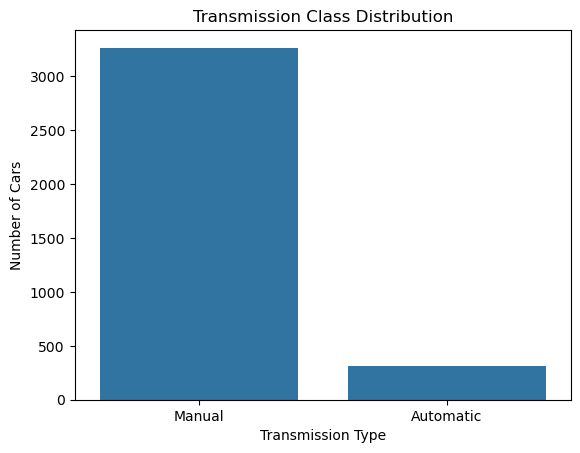

In [4]:
sns.countplot(data=df, x='transmission')

plt.title("Transmission Class Distribution")
plt.xlabel("Transmission Type")
plt.ylabel("Number of Cars")
plt.show()

Manual cars are more common than automatic cars. Therefore, the dataset has an imbalanced class distribution.

In [5]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

X = df[['year', 'selling_price', 'km_driven',
        'fuel', 'seller_type', 'owner']]

y = df['transmission'].map({'Manual': 0, 'Automatic': 1})

numeric_features = ['year', 'selling_price', 'km_driven']
categorical_features = ['fuel', 'seller_type', 'owner']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

Description:
- One-Hot Encoding converts categorical data into numerical form.
- StandardScaler scales numerical features.
- The name column is excluded because it is not needed for this model.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Class Counts:")
print(y_train.value_counts())

print("\nTesting Class Counts:")
print(y_test.value_counts())

Training Records: 2861
Testing Records: 716

Training Class Counts:
transmission
0    2611
1     250
Name: count, dtype: int64

Testing Class Counts:
transmission
0    654
1     62
Name: count, dtype: int64


The dataset is divided into 80% training data and 20% testing data. Stratified splitting maintains the class proportions in both sets.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

print("Intercept:",
      model.named_steps['classifier'].intercept_)

print("Coefficients:",
      model.named_steps['classifier'].coef_)

Model trained successfully!
Intercept: [-2.73513668]
Coefficients: [[-0.312584    1.92784355 -0.03811943 -0.57798345 -0.65049046  0.88902138
  -0.34385061  0.64466402  0.45674633 -0.46880886 -0.02657659 -0.02949372
   0.15514092  0.31996276 -1.12754168  0.64329259]]


Logistic Regression is trained using the training dataset. It predicts the probability of a car having automatic transmission.

Why not Linear Regression? Linear Regression can produce values outside 0 and 1, whereas Logistic Regression uses the sigmoid function to produce probabilities between 0 and 1.

In [8]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Probability': y_prob,
    'Predicted': y_pred
})

print(results.head(10))

   Actual  Probability  Predicted
0       0     0.033060          0
1       0     0.035451          0
2       0     0.044066          0
3       0     0.019199          0
4       0     0.072842          0
5       0     0.050880          0
6       0     0.173118          0
7       1     0.110401          0
8       0     0.029527          0
9       0     0.018497          0


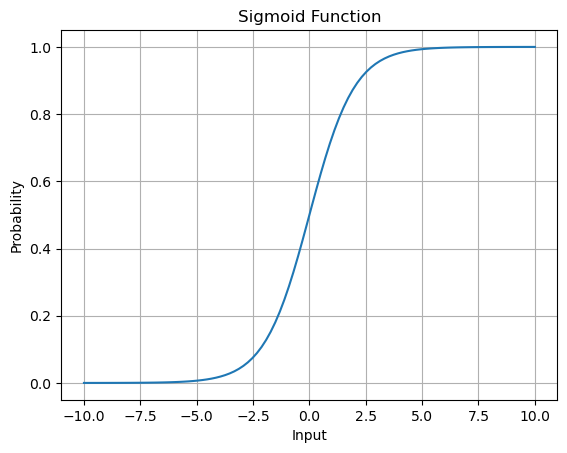

In [9]:
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid()
plt.show()

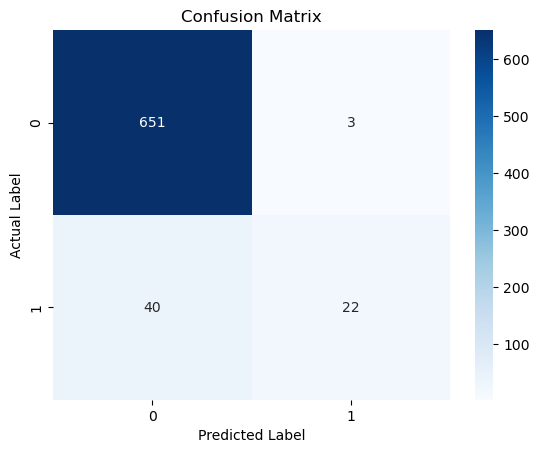

True Negative: 651
False Positive: 3
False Negative: 40
True Positive: 22


In [10]:
from sklearn.metrics import *

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

In [11]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Specificity:", tn / (tn + fp))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9399441340782123
Precision: 0.88
Recall: 0.3548387096774194
Specificity: 0.9954128440366973
F1 Score: 0.5057471264367817
ROC-AUC: 0.8384877182598401

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       654
           1       0.88      0.35      0.51        62

    accuracy                           0.94       716
   macro avg       0.91      0.68      0.74       716
weighted avg       0.94      0.94      0.93       716



In [12]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

base_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, base_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

Baseline Accuracy: 0.9134078212290503
Logistic Regression Accuracy: 0.9399441340782123


The baseline always predicts the majority class. We compare its accuracy with Logistic Regression to check whether our model provides improvement.

In [13]:
for t in [0.3, 0.5, 0.7]:
    pred = (y_prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


Threshold: 0.3
Accuracy: 0.9301675977653632
Precision: 0.6666666666666666
Recall: 0.3870967741935484
F1 Score: 0.4897959183673469

Threshold: 0.5
Accuracy: 0.9399441340782123
Precision: 0.88
Recall: 0.3548387096774194
F1 Score: 0.5057471264367817

Threshold: 0.7
Accuracy: 0.9385474860335196
Precision: 1.0
Recall: 0.2903225806451613
F1 Score: 0.45


We compare thresholds 0.3, 0.5 and 0.7. A lower threshold generally increases recall, while a higher threshold generally increases precision.

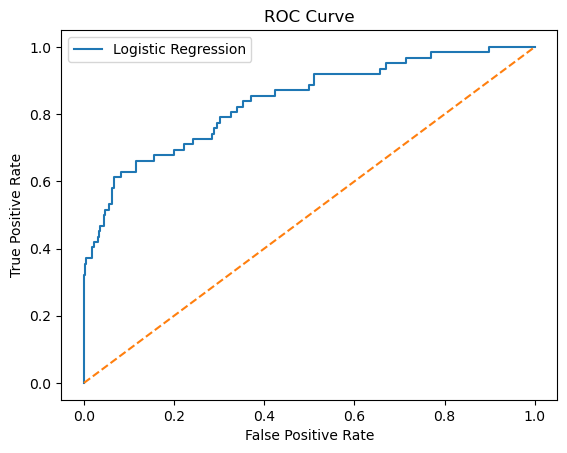

In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], '--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

The ROC curve shows how well the model separates manual and automatic cars at different thresholds.

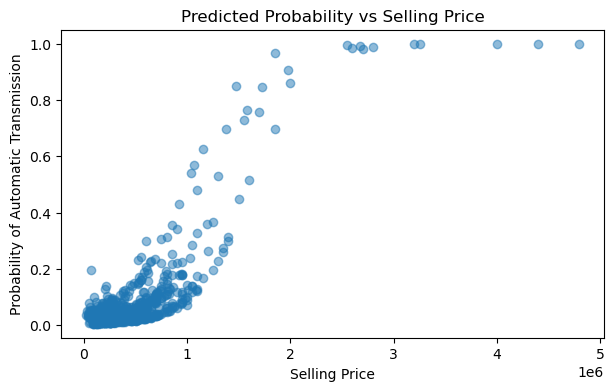

In [15]:
plt.figure(figsize=(7, 4))

plt.scatter(X_test['selling_price'], y_prob, alpha=0.5)

plt.title("Predicted Probability vs Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Probability of Automatic Transmission")
plt.show()

In [16]:
new_car = pd.DataFrame({
    'year': [2018],
    'selling_price': [500000],
    'km_driven': [30000],
    'fuel': ['Petrol'],
    'seller_type': ['Individual'],
    'owner': ['First Owner']
})

prob = model.predict_proba(new_car)[0][1]

print("Automatic Probability:", prob)
print("Predicted Class:",
      "Automatic" if prob >= 0.5 else "Manual")

Automatic Probability: 0.055532368936524766
Predicted Class: Manual


In [17]:
train_pred = model.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred))

Training Accuracy: 0.9328905976931143
Testing Accuracy: 0.9399441340782123


Logistic Regression was used to classify cars into manual and automatic transmission categories. The model was evaluated using accuracy, precision, recall, specificity, F1-score and ROC-AUC. The results help understand the model's classification performance. The model provides probability-based predictions and should not be treated as a guaranteed result.